# Efficient DiD

To estimate the effect on one cohort in one period, Callaway-Sant'Anna makes one
comparison: that cohort against the never-treated units, from the period before
treatment. If parallel trends holds in *every* pre-treatment period, many other
comparisons are valid too, and each carries information. The estimator of Chen,
Sant'Anna & Xie (2025) asks **how to combine all the valid comparisons so that the
estimate is as precise as the data allow, and what you must assume to do it.**

**What you'll learn**

- The two versions of parallel trends, PT-Post and PT-All, and what each one buys
- How to fit `EfficientDiD` and read group-time, event-study and cohort effects
- How large the precision gain is, and that it comes from the stronger assumption
- How to test the stronger assumption against the weaker one
- What the weight and conditioning diagnostics show

**Prerequisites:** [Staggered DiD](02_staggered_did.ipynb) and
[Parallel Trends Diagnostics](04_parallel_trends.ipynb).

In [1]:
import warnings

import numpy as np
import pandas as pd

from diff_diff import (
    CallawaySantAnna,
    EfficientDiD,
    ImputationDiD,
    generate_staggered_data,
    plot_event_study,
)

## What it estimates and assumes

**Target parameter.** The same as Callaway-Sant'Anna: ATT(g, t), the average effect in
period t on the cohort first treated in period g, and averages of those (overall, by
time since treatment, by cohort).

**Identifying assumptions.** No anticipation, absorbing treatment and a balanced panel,
plus one of two versions of parallel trends:

- **PT-Post** (`pt_assumption="post"`): the treated cohort and the never-treated units
  would have moved in parallel from the period just before treatment onward. This is
  the assumption behind Callaway-Sant'Anna with never-treated controls. There is one
  valid comparison per ATT(g, t), and the estimator reproduces Callaway-Sant'Anna's
  post-treatment estimates.
- **PT-All** (`pt_assumption="all"`, the default): parallel trends holds for all groups
  in all periods. This is a stronger assumption. It makes many comparisons valid. Each
  one builds the cohort's untreated change in two steps through a baseline period. The
  change up to the baseline comes from a comparison group for which that baseline is
  still pre-treatment: the never-treated units, another cohort, or the target cohort
  itself. The change from the baseline to period t comes from the never-treated units.

Each valid comparison is an unbiased estimate of the same ATT(g, t), with its own
variance, and they are correlated. The estimator takes the combination with the
smallest variance: weights proportional to the inverse of the comparisons' covariance
matrix, as in generalised least squares. Under PT-All this reaches the lowest variance
any regular estimator can have asymptotically (the semiparametric efficiency bound).

**What would violate it.** Under PT-All, a cohort that was on a different path at *any*
point before treatment, even long before. The extra comparisons then bring bias with
their precision. PT-Post is exposed only to differences from the last pre-treatment
period onward. The efficiency is not free: it is paid for with the assumption.

## Simulated data

A balanced panel of 300 units over 10 periods (0 to 9). Cohorts start treatment in
periods 3, 5 and 7, and 90 units are never treated. The true effect is 2.0 in every
treated period, and parallel trends holds in all periods, so PT-All is true.

In [2]:
TRUE_ATT = 2.0

data = generate_staggered_data(
    n_units=300,
    n_periods=10,
    treatment_effect=TRUE_ATT,
    dynamic_effects=False,  # constant effect: the same in every period after treatment
    seed=42,
)
fit_args = dict(outcome="outcome", unit="unit", time="period", first_treat="first_treat")

cohort_sizes = data.groupby("unit")["first_treat"].first().value_counts().sort_index()
print("Units by first treated period (0 = never treated):")
print(cohort_sizes.to_string())
print(f"\nTrue ATT: {TRUE_ATT}")

Units by first treated period (0 = never treated):
first_treat
0    90
3    60
5    75
7    75

True ATT: 2.0


## Fitting the estimator

Standard errors come from each unit's influence function, one value per unit, so
inference is at the unit level. The summary labels this HC1.

In [3]:
results = EfficientDiD(pt_assumption="all").fit(data, **fit_args)

print(results.summary())

                   Efficient DiD (Chen-Sant'Anna-Xie 2025) Results                   

Total observations:                  3000
Treated units:                        210
Control units:                         90
Treatment cohorts:                      3
Time periods:                          10
PT assumption:                        all
Estimation path:               no covariates

Variance estimator:            HC1 heteroskedasticity-robust
-------------------------------------------------------------------------------------
                   Overall Average Treatment Effect on the Treated                   
-------------------------------------------------------------------------------------
Parameter           Estimate    Std. Err.     t-stat      P>|t|   Sig.
-------------------------------------------------------------------------------------
ATT                   1.9808       0.0366     54.066     0.0000    ***
--------------------------------------------------------------------

In [4]:
print(f"Estimate: {results.att:.3f}  (SE {results.se:.4f})")
print(f"95% CI:   [{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]")
print(f"True ATT: {TRUE_ATT:.3f}")

Estimate: 1.981  (SE 0.0366)
95% CI:   [1.909, 2.053]
True ATT: 2.000


The estimate is 1.98 with a 95% interval of [1.91, 2.05], which contains the true effect
of 2.0. "Control units: 90" is the never-treated group; under PT-All the other cohorts
also contribute comparisons in their own pre-treatment periods.

## PT-All against PT-Post

Fit the same data under the weaker assumption, and with Callaway-Sant'Anna.

In [5]:
results_post = EfficientDiD(pt_assumption="post").fit(data, **fit_args)
callaway = CallawaySantAnna().fit(data, **fit_args)

print(f"{'Estimator':<24} {'ATT':>8} {'SE':>8} {'95% CI':>18} {'covers 2.0':>11}")
for name, fit in [
    ("EfficientDiD, PT-All", results),
    ("EfficientDiD, PT-Post", results_post),
    ("CallawaySantAnna", callaway),
]:
    lower, upper = fit.conf_int
    print(
        f"{name:<24} {fit.att:>8.4f} {fit.se:>8.4f} {f'[{lower:.3f}, {upper:.3f}]':>18} "
        f"{str(lower <= TRUE_ATT <= upper):>11}"
    )

print(f"\nPT-All SE as a share of the PT-Post SE: {results.se / results_post.se:.0%}")

Estimator                     ATT       SE             95% CI  covers 2.0
EfficientDiD, PT-All       1.9808   0.0366     [1.909, 2.053]        True
EfficientDiD, PT-Post      1.9754   0.0528     [1.872, 2.079]        True
CallawaySantAnna           1.9754   0.0528     [1.872, 2.079]        True

PT-All SE as a share of the PT-Post SE: 69%


Under PT-Post the estimator returns exactly the Callaway-Sant'Anna estimate and standard
error: with one valid comparison there is nothing to combine. Under PT-All the standard
error is 69% of that, so the interval is about 30% shorter. All three intervals contain
the true effect.

### Is the gain systematic?

One dataset could be luck. The next cell repeats the comparison on ten simulated panels.

In [6]:
rows = []
for seed in range(10):
    panel = generate_staggered_data(
        n_units=200, n_periods=8, treatment_effect=TRUE_ATT, dynamic_effects=False, seed=seed
    )
    efficient = EfficientDiD(pt_assumption="all").fit(panel, **fit_args)
    baseline = CallawaySantAnna().fit(panel, **fit_args)
    rows.append({"efficient_se": efficient.se, "callaway_se": baseline.se})

ses = pd.DataFrame(rows)
ses["ratio"] = ses["efficient_se"] / ses["callaway_se"]
print(ses.round(4).to_string())
print()
print(f"Mean ratio: {ses['ratio'].mean():.3f}   (range {ses['ratio'].min():.3f} to {ses['ratio'].max():.3f})")

   efficient_se  callaway_se   ratio
0        0.0447       0.0683  0.6547
1        0.0521       0.0693  0.7516
2        0.0491       0.0700  0.7012
3        0.0481       0.0641  0.7502
4        0.0446       0.0669  0.6671
5        0.0489       0.0658  0.7433
6        0.0457       0.0684  0.6675
7        0.0478       0.0745  0.6415
8        0.0426       0.0666  0.6399
9        0.0477       0.0674  0.7079

Mean ratio: 0.692   (range 0.640 to 0.752)


The ratio is between 0.64 and 0.75 in every panel and 0.69 on average. The gain is
systematic, for data where PT-All holds. What this exercise cannot show is the other
side of the trade: these panels satisfy PT-All by construction, so the extra comparisons
never bring any bias with them.

### Testing PT-All against PT-Post

Because the two fits estimate the same effects under PT-All, a large gap between them is
evidence against the stronger assumption. `EfficientDiD.hausman_pretest` formalises that
comparison on the post-treatment event-study estimates.

In [7]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    hausman = EfficientDiD.hausman_pretest(data, **fit_args)

print(f"Statistic: {hausman.statistic:.3f}  (df {hausman.df})")
print(f"p-value:   {hausman.p_value:.3f}")
print(f"Recommendation: {hausman.recommendation}")
print()
for warning in caught:
    print(f"Warning: {warning.message}")

Statistic: 8.318  (df 6)
p-value:   0.216
Recommendation: pt_all



The test does not reject (p = 0.216): the two sets of estimates are compatible with each
other, as they should be when PT-All holds.

Read the result with two cautions. The warning is the first: the statistic is built from
the difference between the two estimators' covariance matrices. In the population that
difference is positive semidefinite when PT-All holds, because one estimator is
efficient; in a finite sample the estimated difference need not be. When it is
not, the test is less reliable. The second is the general one: this is a pre-test. Not
rejecting is not evidence that PT-All holds, and choosing the estimator by the outcome
of a test changes the properties of what you then report. Decide between PT-All and
PT-Post on what you know about the setting, and use the test as a check.

## Group-time effects

The ATT(g, t) estimates are the building blocks of every summary.

In [8]:
group_time = results.to_dataframe(level="group_time")

print(f"{len(group_time)} group-time estimates")
print(group_time.head(9).round(3).to_string(index=False))

27 group-time estimates
 group  time  effect    se  t_stat  p_value  conf_int_lower  conf_int_upper
     3     1   0.078 0.077   1.015    0.310          -0.073           0.228
     3     2  -0.059 0.084  -0.700    0.484          -0.223           0.105
     3     3   2.059 0.093  22.166    0.000           1.877           2.242
     3     4   2.010 0.082  24.545    0.000           1.849           2.170
     3     5   1.997 0.093  21.455    0.000           1.815           2.180
     3     6   1.931 0.079  24.424    0.000           1.776           2.086
     3     7   2.040 0.099  20.587    0.000           1.846           2.235
     3     8   1.948 0.098  19.856    0.000           1.756           2.140
     3     9   1.987 0.083  24.003    0.000           1.825           2.149


The first two rows are pre-treatment periods for the cohort treated in period 3, and are
near zero. Period 0 does not appear: it is the common first period against which every
comparison is differenced.

## Event study

`aggregate("event_study")` averages the group-time effects by time since treatment.

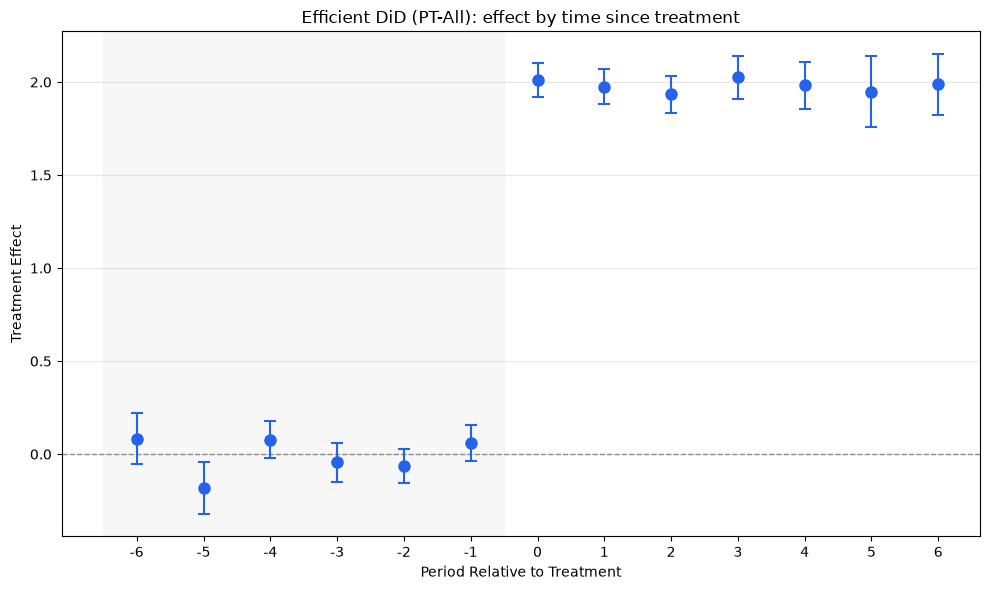

In [9]:
es = results.aggregate("event_study")

ax = plot_event_study(es, title="Efficient DiD (PT-All): effect by time since treatment", show=False)

In [10]:
columns = ["event_time", "att", "se", "conf_int_lower", "conf_int_upper"]
print(es.to_dataframe()[columns].round(3).to_string(index=False))

 event_time    att    se  conf_int_lower  conf_int_upper
         -6  0.083 0.070          -0.055           0.221
         -5 -0.180 0.071          -0.319          -0.041
         -4  0.077 0.051          -0.023           0.177
         -3 -0.045 0.054          -0.150           0.061
         -2 -0.064 0.047          -0.157           0.028
         -1  0.059 0.048          -0.036           0.154
          0  2.010 0.047           1.918           2.103
          1  1.975 0.048           1.881           2.070
          2  1.934 0.050           1.836           2.033
          3  2.026 0.059           1.911           2.141
          4  1.982 0.064           1.856           2.108
          5  1.948 0.098           1.756           2.140
          6  1.987 0.083           1.825           2.149


The post-treatment estimates are close to 2.0 at every horizon.

The pre-treatment estimates are a useful lesson. Parallel trends holds in this
simulation, and yet the interval at event time -5 excludes zero. With six pointwise 95%
intervals, at least one excluding zero is common when nothing is wrong: about a quarter
of the time if the six were independent. A single individually significant pre-treatment coefficient is weak evidence,
just as six insignificant ones would be weak evidence the other way. Look at the size
and pattern of the coefficients, not at a count of stars, and see
[Pre-Trends Power](07_pretrends_power.ipynb) and
[Honest DiD Sensitivity](05_honest_did.ipynb). Neither takes this estimator's event study. Run them on a
`CallawaySantAnna(base_period="universal")` fit of the same data, and read what they
report as a statement about that fit's comparisons, not this one's.

## Effects by cohort

In [11]:
columns = ["label", "att", "se", "conf_int_lower", "conf_int_upper"]
print(results.aggregate("group").to_dataframe()[columns].round(3).to_string(index=False))

label   att    se  conf_int_lower  conf_int_upper
    3 1.996 0.050           1.898           2.094
    5 1.993 0.048           1.898           2.088
    7 1.932 0.054           1.826           2.038


## Bootstrap inference

Standard errors are analytical by default. `n_bootstrap` switches to a multiplier
bootstrap, which perturbs each unit's contribution with random weights
(`bootstrap_weights`: `"rademacher"` by default, `"mammen"` or `"webb"`).

In [12]:
print(f"{'Inference':<22} {'ATT':>7} {'SE':>8} {'95% CI':>18}")
print(f"{'Analytical':<22} {results.att:>7.3f} {results.se:>8.4f} {f'[{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]':>18}")
for weights in ["rademacher", "mammen", "webb"]:
    fit = EfficientDiD(pt_assumption="all", n_bootstrap=999, bootstrap_weights=weights, seed=42).fit(
        data, **fit_args
    )
    label = f"Bootstrap, {weights}"
    print(f"{label:<22} {fit.att:>7.3f} {fit.se:>8.4f} {f'[{fit.conf_int[0]:.3f}, {fit.conf_int[1]:.3f}]':>18}")

Inference                  ATT       SE             95% CI
Analytical               1.981   0.0366     [1.909, 2.053]
Bootstrap, rademacher    1.981   0.0365     [1.906, 2.051]
Bootstrap, mammen        1.981   0.0373     [1.910, 2.052]
Bootstrap, webb          1.981   0.0365     [1.908, 2.052]


The bootstrap standard errors agree with the analytical one to the third decimal, for
all three weight distributions.

## Diagnostics: weights and conditioning

Two attributes show what the estimator did for each ATT(g, t):

- **`efficient_weights`**: the weight on each valid comparison. They sum to one.
- **`omega_condition_numbers`**: the condition number of the covariance matrix of the
  comparisons, whose inverse gives the weights.

In [13]:
weights_56 = results.efficient_weights[(5, 6)]
print(f"ATT(5, 6) combines {len(weights_56)} comparisons; weights sum to {weights_56.sum():.4f}")
print(f"Largest weight {weights_56.max():.3f}, smallest {weights_56.min():.3f}")
print()

n_comparisons = pd.Series({key: len(w) for key, w in results.efficient_weights.items()})
conditioning = pd.Series(results.omega_condition_numbers)
print(f"Comparisons per ATT(g, t): {n_comparisons.min()} to {n_comparisons.max()}")
print(f"Condition numbers: {conditioning.min():.0f} to {conditioning.max():.0f} (median {conditioning.median():.0f})")

ATT(5, 6) combines 21 comparisons; weights sum to 1.0000
Largest weight 0.346, smallest -0.125

Comparisons per ATT(g, t): 20 to 21
Condition numbers: 79 to 161 (median 104)


ATT(5, 6), the effect in period 6 on the cohort treated in period 5, combines 21
comparisons. Each pairs a comparison group with a baseline period: the comparison group
supplies the change from period 0 to the baseline, and the never-treated units supply
the change from the baseline to period 6. The 21 pairs are the never-treated units with
each of the nine baseline periods 1 to 9, and the cohorts treated in periods 3, 5 and 7
with their own pre-treatment periods (2, 4 and 6 of them). Cohort 5 is among its own
comparison groups. A pair is valid when the baseline is a pre-treatment period *for the
comparison group*. Period 0 is never a baseline: every comparison is already
differenced against it.

Some weights are negative. That is ordinary for a minimum-variance combination of
correlated estimates, and it is not the negative-weights problem of two-way fixed
effects: here every comparison is a valid estimate of the same ATT(g, t), so any set of
weights that sums to one targets that effect.

The condition numbers say how close the comparisons are to being redundant. Values
around 100, as here, are unremarkable, and there is no universal threshold. By default
the estimator adds a small ridge (`omega_ridge`) before inverting, which keeps the
weights stable when some comparisons are nearly redundant. Condition numbers many
orders of magnitude larger would be a reason to look closer.

## Anticipation

`anticipation=k` treats the `k` periods before the recorded treatment date as treated.

In [14]:
with_anticipation = EfficientDiD(pt_assumption="all", anticipation=1).fit(data, **fit_args)

print(f"ATT, no anticipation:        {results.att:.3f}")
print(f"ATT, one period anticipated: {with_anticipation.att:.3f}")

ATT, no anticipation:        1.981
ATT, one period anticipated: 1.665


As in [Imputation DiD](11_imputation_did.ipynb), the lower number is the wrong one for
this data. There is no anticipation in the simulation, so the period before treatment
has no effect, and counting it as treated averages zeros into the estimate. Set
`anticipation` when you expect a response before the recorded date, not as a routine
check.

## Comparison with Imputation DiD

Imputation DiD also relies on parallel trends in all periods and uses every untreated
observation. The two are efficient under different conditions: Efficient DiD under
PT-All with an unrestricted error covariance, Imputation DiD when the errors have
equal variance and are uncorrelated across units and periods.

In [15]:
imputation = ImputationDiD().fit(data, **fit_args)

print(f"{'Estimator':<24} {'ATT':>8} {'SE':>8} {'95% CI':>18} {'covers 2.0':>11}")
for name, fit in [
    ("EfficientDiD, PT-All", results),
    ("ImputationDiD", imputation),
    ("CallawaySantAnna", callaway),
]:
    lower, upper = fit.conf_int
    print(
        f"{name:<24} {fit.att:>8.4f} {fit.se:>8.4f} {f'[{lower:.3f}, {upper:.3f}]':>18} "
        f"{str(lower <= TRUE_ATT <= upper):>11}"
    )

Estimator                     ATT       SE             95% CI  covers 2.0
EfficientDiD, PT-All       1.9808   0.0366     [1.909, 2.053]        True
ImputationDiD              1.9817   0.0369     [1.909, 2.054]        True
CallawaySantAnna           1.9754   0.0528     [1.872, 2.079]        True


Efficient DiD and Imputation DiD are equally precise here, to within 1%, and both are
about 30% more precise than Callaway-Sant'Anna. This simulation satisfies the conditions
of both: parallel trends in all periods, and independent errors with equal variance. On
other data either can come out ahead. Neither dominates, and the choice between them
should rest on which assumptions you are prepared to defend.

## Summary

- Efficient DiD targets the same ATT(g, t) as Callaway-Sant'Anna and combines every
  comparison that the assumed version of parallel trends makes valid, with
  variance-minimising weights.
- Under PT-Post it reproduces Callaway-Sant'Anna's post-treatment estimates. Under
  PT-All it is more precise, here by about 30%.
- The gain is bought with a stronger assumption: parallel trends in every pre-treatment
  period. `hausman_pretest` compares the two fits, with the usual limits of a pre-test.
- Event-study, cohort and overall summaries come from one fit.

## When to use it and when not to

Use PT-All when parallel trends over the whole pre-treatment window is credible and
precision matters. Use PT-Post, or Callaway-Sant'Anna, when early pre-treatment periods
are suspect: a precise estimate of the wrong quantity is not an improvement. Do not
choose between them by which gives the narrower interval or the more convenient
estimate; decide on the assumption first, and report the other as a check. The estimator
needs a balanced panel and absorbing treatment.

### Parameter reference

| Parameter | Default | Description |
|---|---|---|
| `pt_assumption` | `"all"` | `"all"` (many comparisons) or `"post"` (one, as Callaway-Sant'Anna) |
| `control_group` | `"never_treated"` | `"never_treated"` or `"last_cohort"` |
| `anticipation` | 0 | Periods of anticipation |
| `n_bootstrap` | 0 | Bootstrap draws (0 = analytical standard errors) |
| `bootstrap_weights` | `"rademacher"` | `"rademacher"`, `"mammen"` or `"webb"` |
| `seed` | `None` | Random seed |
| `alpha` | 0.05 | Significance level |

Covariates are passed to `fit(covariates=[...])`.

## Next steps

- [Imputation DiD](11_imputation_did.ipynb): efficiency under a different condition
- [Wooldridge ETWFE](16_wooldridge_etwfe.ipynb): a regression route to the same
  group-time effects
- [Honest DiD Sensitivity](05_honest_did.ipynb): results under bounded violations of
  parallel trends, run on a Callaway-Sant'Anna fit of the same data

## References

- Chen, X., Sant'Anna, P. H. C., & Xie, H. (2025). "Efficient Difference-in-Differences and
  Event Study Estimators." arXiv:2506.17729.
- Callaway, B., & Sant'Anna, P. H. C. (2021). "Difference-in-Differences with Multiple Time
  Periods." *Journal of Econometrics*, 225(2), 200-230.